# Cross-sectional Momentum Strategy

I backtest a monthly long-short momentum strategy on 10 US large caps (AAPL, MSFT, GOOGL, AMZN, META, TSLA, NVDA, JPM, JNJ, XOM) using daily prices from Yahoo Finance (2020-2024).

**Method.** Each month, stocks are ranked by their past 12 monthly returns (summed). The strategy goes long the top 3 and short the bottom 3 with equal weights, using the signal from the previous month-end, so there is no look-ahead. Performance is compared with the S&P 500 (SPY).

**Result.** Annualised return 7.17%, annualised volatility 30.53%, Sharpe ratio 0.23 (no risk-free rate subtracted), maximum drawdown -42.44%. The strategy underperformed SPY over the period.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

In [2]:
data = yf.download('AAPL', start='2022-01-01', end='2025-01-01')
print(data.head())

[*********************100%***********************]  1 of 1 completed

Price            Close        High         Low        Open     Volume
Ticker            AAPL        AAPL        AAPL        AAPL       AAPL
2022-01-03  177.786407  178.636229  173.586202  173.703413  104487900
2022-01-04  175.529968  178.694788  174.963426  178.391984   99310400
2022-01-05  170.860916  175.989088  170.587415  175.442085   94537600
2022-01-06  168.008682  171.232108  167.657036  168.692436   96904000
2022-01-07  168.174728  170.099015  167.061183  168.878022   86709100


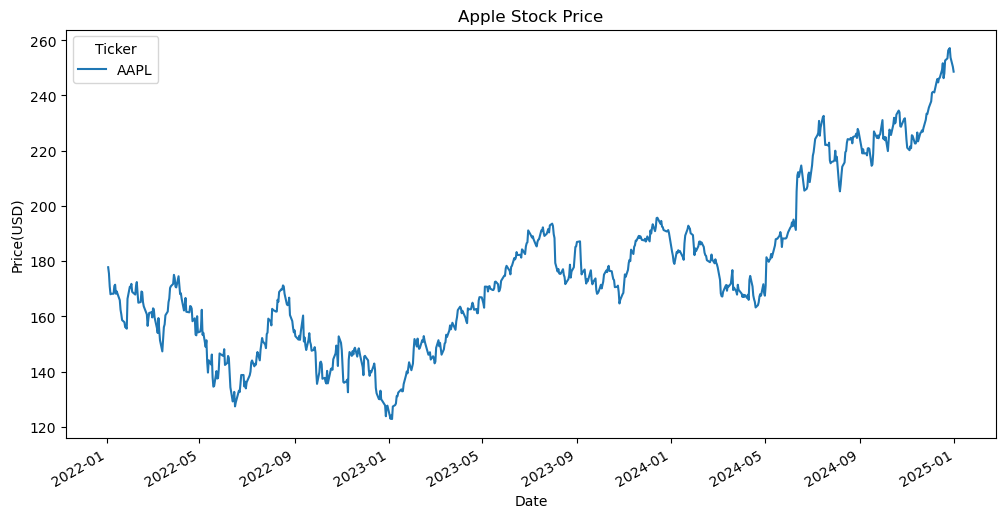

In [3]:
data['Close'].plot(figsize=(12,6),title='Apple Stock Price')
plt.xlabel('Date')
plt.ylabel('Price(USD)')
plt.show()

2022-01-03         NaN
2022-01-04   -0.012692
2022-01-05   -0.026600
2022-01-06   -0.016693
2022-01-07    0.000988
2022-01-10    0.000116
2022-01-11    0.016784
2022-01-12    0.002570
2022-01-13   -0.019028
2022-01-14    0.005111
Name: AAPL, dtype: float64


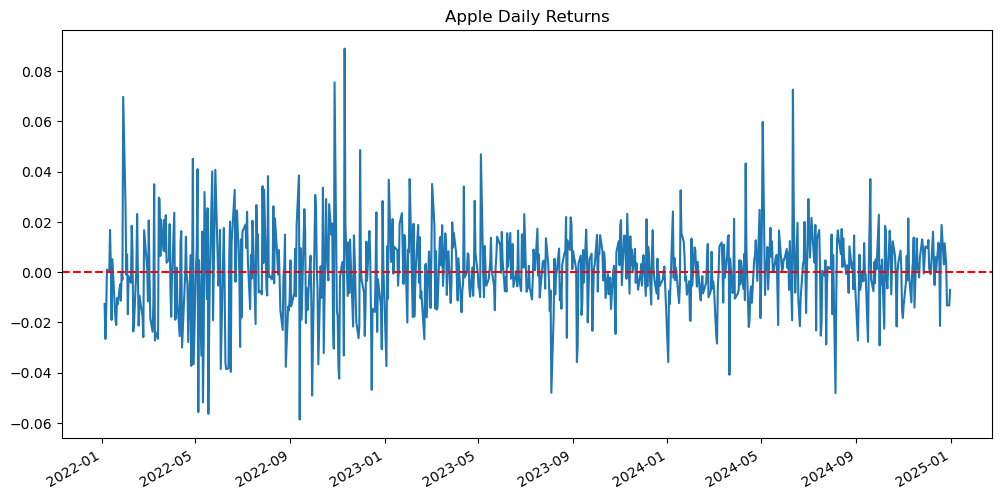

In [4]:
returns = data['Close'].squeeze().pct_change()
print(returns.head(10))
returns.plot(figsize=(12,6),title='Apple Daily Returns')
plt.axhline(y=0, color = 'red',linestyle='--')
plt.show()

In [5]:
mean_ret = returns.mean()
std_ret = returns.std()

print(f"average daily return: {mean_ret:.4f}")
print(f"standard deviation: {std_ret:.4f}")
print(f"annual return: {mean_ret * 252:.4f}")
print(f"annual volatility: {std_ret * np.sqrt(252):.4f}")
print(f"Sharpe ratio: {(mean_ret*252)/(std_ret * np.sqrt(252)):.4f}")

average daily return: 0.0006
standard deviation: 0.0171
annual return: 0.1490
annual volatility: 0.2709
Sharpe ratio: 0.5498


In [6]:
tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 
           'TSLA', 'NVDA', 'JPM', 'JNJ', 'XOM']
prices = yf.download(tickers, start='2020-01-01', end='2025-01-01')['Close']
print(prices.shape)
print(prices.head())

[*********************100%***********************]  10 of 10 completed

(1258, 10)
Ticker           AAPL       AMZN      GOOGL         JNJ         JPM  \
2020-01-02  72.271545  94.900497  67.788933  121.338531  117.313942   
2020-01-03  71.568909  93.748497  67.434303  119.933701  115.765808   
2020-01-06  72.139198  95.143997  69.231720  119.784058  115.673744   
2020-01-07  71.799942  95.343002  69.097977  120.515610  113.707268   
2020-01-08  72.954910  94.598503  69.589798  120.498955  114.594284   

Ticker            META        MSFT      NVDA       TSLA        XOM  
2020-01-02  207.789856  151.544281  5.957139  28.684000  52.606396  
2020-01-03  206.690384  149.657257  5.861789  29.534000  52.183475  
2020-01-06  210.583099  150.044113  5.886371  30.102667  52.584141  
2020-01-07  211.038757  148.676056  5.957634  31.270666  52.153793  
2020-01-08  213.178268  151.044205  5.968809  32.809334  51.367298  


In [7]:
monthly_prices = prices.resample('ME').last()
monthly_returns = monthly_prices.pct_change()

print(monthly_returns.tail())

Ticker          AAPL      AMZN     GOOGL       JNJ       JPM      META  \
2024-08-31  0.032353 -0.045352 -0.047569  0.058720  0.056391  0.097888   
2024-09-30  0.017467  0.043866  0.016465 -0.022911 -0.062011  0.099127   
2024-10-31 -0.030429  0.000376  0.031715 -0.013575  0.058901 -0.008490   
2024-11-30  0.051707  0.115290 -0.012623 -0.022559  0.125270  0.011875   
2024-12-31  0.055155  0.055318  0.121734 -0.067028 -0.040085  0.020306   

Ticker          MSFT      NVDA      TSLA       XOM  
2024-08-31 -0.001095  0.020082 -0.077390  0.002526  
2024-09-30  0.031548  0.017428  0.221942 -0.006105  
2024-10-31 -0.055659  0.093215 -0.045025 -0.003754  
2024-11-30  0.044192  0.041353  0.381469  0.018405  
2024-12-31 -0.004628 -0.028577  0.170008 -0.088081  


In [8]:
momentum = monthly_returns.rolling(12).sum()
latest_momentum = momentum.iloc[-1].sort_values(ascending=False)
print("the rank of momentum in past 12 months:")
print(latest_momentum)

the rank of momentum in past 12 months:
Ticker
NVDA     1.113187
TSLA     0.651615
META     0.565252
AMZN     0.391580
JPM      0.389228
GOOGL    0.328144
AAPL     0.287677
MSFT     0.137316
XOM      0.118379
JNJ     -0.036905
Name: 2024-12-31 00:00:00, dtype: float64


In [9]:
long_short_returns = []
for i in range(12, len(monthly_returns)):
    prev_momentum = momentum.iloc[i-1].dropna()
    
    long_stocks = prev_momentum.nlargest(3).index
    short_stocks = prev_momentum.nsmallest(3).index
    
    curr_returns = monthly_returns.iloc[i]
    
    portfolio_return = curr_returns[long_stocks].mean() - curr_returns[short_stocks].mean()
    long_short_returns.append(portfolio_return)

strategy_returns = pd.Series(long_short_returns, 
                              index=monthly_returns.index[12:])
print(strategy_returns.tail())

2024-08-31    0.029587
2024-09-30   -0.046127
2024-10-31    0.068660
2024-11-30    0.046153
2024-12-31    0.037127
Freq: ME, dtype: float64


annul return: 7.17%
annul volatility: 30.53%
Sharpe Ratio: 0.23
Max Drawdown: -42.44%


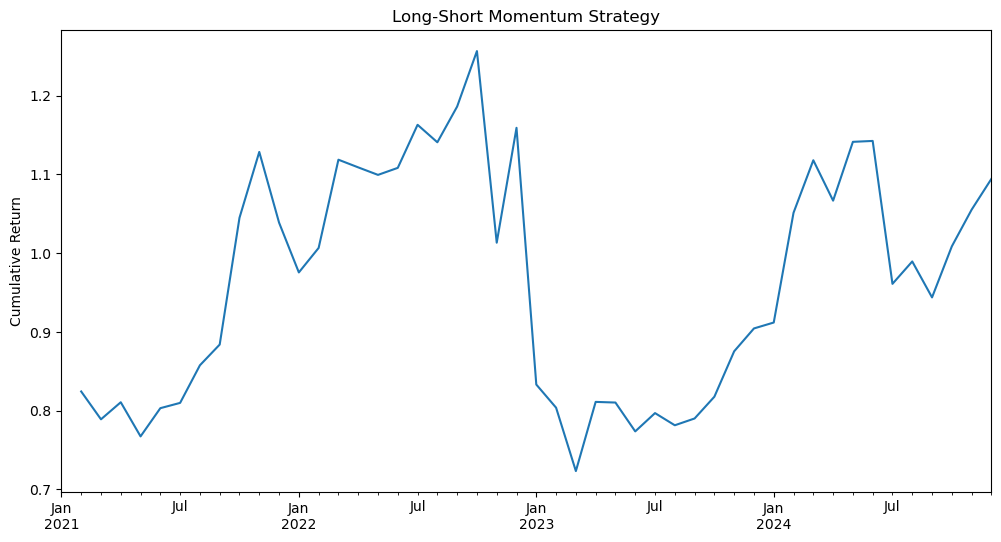

In [10]:
ann_return = strategy_returns.mean() * 12
ann_vol = strategy_returns.std() * np.sqrt(12)
sharpe = ann_return / ann_vol

# Max Drawdown
cumulative = (1 + strategy_returns).cumprod()
rolling_max = cumulative.cummax()
drawdown = (cumulative - rolling_max) / rolling_max
max_drawdown = drawdown.min()

print(f"annul return: {ann_return:.2%}")
print(f"annul volatility: {ann_vol:.2%}")
print(f"Sharpe Ratio: {sharpe:.2f}")
print(f"Max Drawdown: {max_drawdown:.2%}")

# cumulative return curve
cumulative.plot(figsize=(12,6), title='Long-Short Momentum Strategy')
plt.ylabel('Cumulative Return')
plt.show()

[*********************100%***********************]  1 of 1 completed


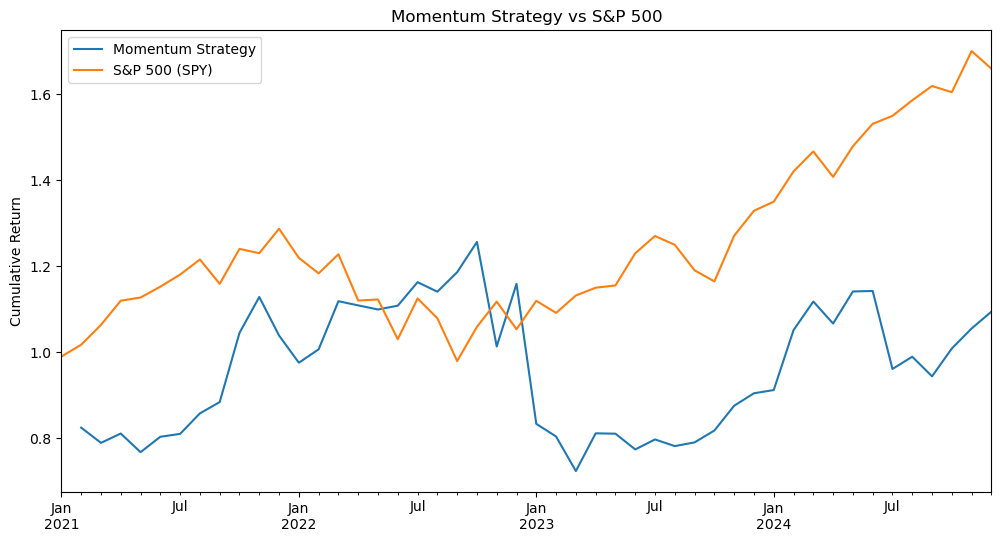

In [11]:
spy = yf.download('SPY', start='2020-01-01', end='2025-01-01')['Close'].squeeze()
spy_ret = spy.resample('ME').last().pct_change()
spy_cum = (1 + spy_ret.loc[strategy_returns.index]).cumprod()

plt.figure(figsize=(12,6))
cumulative.plot(label='Momentum Strategy')
spy_cum.plot(label='S&P 500 (SPY)')
plt.title('Momentum Strategy vs S&P 500')
plt.ylabel('Cumulative Return')
plt.legend()
plt.show()

In [12]:
spy_m = spy_ret.loc[strategy_returns.index]
print(f"SPY annual return: {spy_m.mean()*12:.2%}")
print(f"SPY annual volatility: {spy_m.std()*np.sqrt(12):.2%}")
print(f"SPY Sharpe: {(spy_m.mean()*12)/(spy_m.std()*np.sqrt(12)):.2f}")

SPY annual return: 14.01%
SPY annual volatility: 16.10%
SPY Sharpe: 0.87


## Limitations

- **Hindsight in the stock universe.** The 10 stocks were hand-picked after the fact and include 2020-2024 winners (NVDA, TSLA, META), so the universe is subject to survivorship and selection bias.
- No transaction costs, borrow fees or slippage, although the strategy rebalances monthly and shorts three stocks.
- The Sharpe ratio is computed without subtracting a risk-free rate.
- Small cross-section (10 stocks), a single sample period (2021-2024) and no out-of-sample test, so the results are noisy.
- Long and short legs are equally weighted and returns are not scaled by capital used, so the reported return approximates, but is not exactly, a return on capital.